# PGML Workflow for a sample dataset

In [1]:
!pip install numpy torch scikit-learn matplotlib cmocean transformers einops mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 9.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 7.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.1/62.1 kB 10.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.9/139.9 kB 16.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 4.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 9.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 7.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.6/137.6 kB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.9/16.9 MB 61.8 MB/s eta 0:00:00:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 539.1/539.1 MB 1.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 519.2/519.2 MB 2.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 5.1 MB/s eta 0:00:00:00:0100

## Dependencies

In [1]:
import sys
import os

import numpy as np
from tqdm import tqdm

import torch
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.optim import AdamW

from common_utils.distributed_training import setup_distributed_training
from common_utils.config import Config
from common_utils.dataloader import create_datasets_lite, create_dataloaders
from common_utils.loss import PhysicsGuidedLoss
from common_utils.early_stopping import EarlyStopping

from FourCastNet.networks.afnonet_wf import AFNONet_Seq2Seq
from FourCastNet.src.trainer import Trainer, run_seq2seq_test

import tempfile
import time


from matplotlib.colors import LinearSegmentedColormap
from matplotlib import pyplot as plt
from IPython.display import Image as IPythonImage

import io
from PIL import Image, ImageFont, ImageDraw


/opt/conda/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:

# No ddp needed
dist_config = setup_distributed_training()
ddp, ddp_rank, ddp_local_rank,ddp_world_size, master_process, device = dist_config.values()

# Setup config
config_path = '/home/jovyan/work/_User-Persistent-Storage_CephBlock_/pgml-scil/FourCastNet/configs/config_lite_sample_data.yaml'
config = Config(filepath=config_path)

project_dir = '/home/jovyan/work/_User-Persistent-Storage_CephBlock_/pgml-scil'

## Setup

## Training

In [3]:
RUN_TIMESTAMP = time.strftime("%Y%m%d_%H%M%S")

# No ddp needed
dist_config = setup_distributed_training()
ddp, ddp_rank, ddp_local_rank,ddp_world_size, master_process, device = dist_config.values()

# Setup config
config_path = '/home/jovyan/work/_User-Persistent-Storage_CephBlock_/pgml-scil/FourCastNet/configs/config_lite_sample_data.yaml'
config = Config(filepath=config_path)
config.timestamp = RUN_TIMESTAMP
config.ddp_world_size = dist.get_world_size() if ddp else 1

print(f"Data loading for DDP rank {ddp_rank}...")
print(f"Creating datasets and dataloaders for DDP rank {ddp_rank}...")

test_dataset = None

# Using data_lite_sample
train_dataset, val_dataset, test_dataset = create_datasets_lite(config, project_dir, ddp_rank, config.ddp_world_size)

train_loader, val_loader, test_loader = create_dataloaders(
        train_dataset, val_dataset, test_dataset, config, test_batch_size=1
)

# Determine input channels from the first batch
# Note: train_loader returns (x, y, idx)
config.in_channels = next(iter(train_loader))[0].shape[2] # (B, T, C, H, W) -> C is at index 2

model = AFNONet_Seq2Seq(
    img_size=(config.image_size, config.image_size), patch_size=(config.patch_size, config.patch_size),
    in_chans=config.in_channels, out_chans=config.out_channels,
    context_len=config.context_len, temporal_patch_size=config.temporal_patch_size,
    embed_dim=config.embed_dim, depth=config.depth, num_blocks=config.num_blocks
).to(device)

loss_fn = PhysicsGuidedLoss(
    use_physics_loss=config.physics_loss,
    fuel_transport_weight=config.get("fuel_transport_weight", 0),
    burned_weight=config.get("burned_weight", 0),
    unburned_weight=config.get("unburned_weight", 0),
    fire_metrics_weight=config.get("fire_metrics_weight", 0),
    ros_method=config.get("ros_method", None),
    mse_weight=config.get("mse_weight", 1.0),
) 


optimizer = AdamW(model.parameters(), lr=config.max_lr, weight_decay=config.weight_decay)
# optimizer = torch.optim.SGD(model.parameters(), lr=config.max_lr, momentum=0.9, weight_decay=config.weight_decay)

scheduler = CosineAnnealingLR(optimizer, T_max=config.max_epochs, eta_min=config.min_lr)
early_stop_criteria = EarlyStopping(patience=config.early_stopping_patience)
grad_accum_steps = config.batch_size // (config.mini_batch_size * config.ddp_world_size)

trainer = Trainer(
    config, model, train_loader, val_loader, loss_fn, optimizer, scheduler,
    early_stop_criteria, grad_accum_steps, ddp, ddp_rank, device
)

trainer.train_loop()

Data loading for DDP rank 0...
Creating datasets and dataloaders for DDP rank 0...


Epoch 10/10: 100%|██████████| 42/42 [00:07<00:00,  5.75it/s, base_mse=0.175, fuel_transport=0.0235, burned=0.176, unburned=0.175, fire_metrics=1.23]


## Testing

In [5]:
config_folder = '/home/jovyan/work/_User-Persistent-Storage_CephBlock_/pgml-scil/FourCastNet/src/results/'
run_seq2seq_test(trainer.model, loss_fn, test_loader, config, config_folder)


=== Beginning Sequence-to-Sequence Test ===


## Load the model

In [6]:

# 0. config
# args_config = 'data_lanl_fire/config.yaml'
# config = Config(filepath=args_config, override_from_env=False, override_from_args=False)
# config.in_channels = 4

# 1. Instantiate the model structure
model = AFNONet_Seq2Seq(
    img_size=(config.image_size, config.image_size), patch_size=(config.patch_size, config.patch_size),
    in_chans=config.in_channels, out_chans=config.out_channels,
    context_len=config.context_len, temporal_patch_size=config.temporal_patch_size,
    embed_dim=config.embed_dim, depth=config.depth, num_blocks=config.num_blocks
)


# 2. Load your weights
model_path = config_folder + 'best_model.pth'
weights = torch.load(model_path, map_location=torch.device('cuda'))
model.load_state_dict(weights['state_dict'])

<All keys matched successfully>

## Visuals

### Plotting functions

In [7]:
def images_to_gif(images, output_path, duration=200, cmap='viridis', vmin=None, vmax=None, start_index=0):
    """
    Convert a list of 2D numpy arrays to an animated GIF.
    
    Args:
        images: list of 2D numpy arrays
        output_path: path to save the GIF (e.g., 'output.gif')
        duration: milliseconds per frame
        cmap: matplotlib colormap
        vmin/vmax: colormap value range (uses global min/max if None)
    """
    frames = []
    vmin = vmin if vmin is not None else min(img.min() for img in images)
    vmax = vmax if vmax is not None else max(img.max() for img in images)

    for i, img in tqdm(enumerate(images), total=len(images), desc="Creating GIF frames"):
        fig, ax = plt.subplots()
        ax.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(f'Time step {i + start_index}')
        ax.axis('off')

        buf = io.BytesIO()
        plt.savefig(buf, format='png', bbox_inches='tight', pad_inches=0)
        plt.close(fig)
        buf.seek(0)
        frames.append(Image.open(buf).convert('RGBA'))

    frames[0].save(
        output_path,
        save_all=True,
        append_images=frames[1:],
        duration=duration,
        loop=0  # 0 = loop forever
    )
    print(f"Saved GIF to {output_path}")



def combine_gifs_side_by_side(gifpath1, gifpath2, outputpath, duration=200, loop=0, gap=10,
                               cmap=None, vmin=0, vmax=1,
                               title1='original', title2='predicted', title_height=30,
                               skip1=0, skip2=0):

    gif1 = Image.open(gifpath1)
    gif2 = Image.open(gifpath2)

    # Skip initial frames
    for _ in range(skip1):
        gif1.seek(gif1.tell() + 1)
    for _ in range(skip2):
        gif2.seek(gif2.tell() + 1)

    # Pre-render colorbar once (same for all frames)
    cb_img = None
    if cmap is not None:
        colorbar_width = 60
        fig, ax = plt.subplots(figsize=(0.6, 3))
        norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
        mpl.colorbar.ColorbarBase(ax, cmap=cmap, norm=norm, orientation='vertical')
        buf = io.BytesIO()
        plt.savefig(buf, format='png', bbox_inches='tight', pad_inches=0.05, dpi=100)
        plt.close(fig)
        buf.seek(0)
        cb_img = Image.open(buf).convert('RGBA')

    try:
        font = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", size=16)
    except Exception:
        font = ImageFont.load_default()

    frames = []
    try:
        while True:
            f1 = gif1.copy().convert('RGBA')
            f2 = gif2.copy().convert('RGBA')

            total_width = f1.width + gap + f2.width
            total_height = title_height + f1.height
            if cb_img is not None:
                cb_resized = cb_img.resize((colorbar_width, f1.height), Image.LANCZOS)
                total_width += gap + colorbar_width

            combined = Image.new('RGBA', (total_width, total_height), (255, 255, 255, 255))
            draw = ImageDraw.Draw(combined)

            # Draw titles
            for text, x_center in [(title1, f1.width // 2), (title2, f1.width + gap + f2.width // 2)]:
                bbox = draw.textbbox((0, 0), text, font=font)
                text_w = bbox[2] - bbox[0]
                draw.text((x_center - text_w // 2, (title_height - (bbox[3] - bbox[1])) // 2),
                          text, fill=(0, 0, 0, 255), font=font)

            # Paste frames below titles
            combined.paste(f1, (0, title_height))
            combined.paste(f2, (f1.width + gap, title_height))

            if cb_img is not None:
                combined.paste(cb_resized, (f1.width + gap + f2.width + gap, title_height))

            frames.append(combined)

            gif1.seek(gif1.tell() + 1)
            gif2.seek(gif2.tell() + 1)
    except EOFError:
        pass

    frames[0].save(
        outputpath,
        save_all=True,
        append_images=frames[1:],
        duration=duration,
        loop=loop
    )
    print(f"Saved combined GIF to {outputpath}")

### Selected test input

In [8]:
test_features = np.load('/home/jovyan/work/_User-Persistent-Storage_CephBlock_/pgml-scil/data_lite_sample/test-features-713.npy')
test_features = test_features.transpose(0,3,1,2)

test_y = np.load('/home/jovyan/work/_User-Persistent-Storage_CephBlock_/pgml-scil/data_lite_sample/test-y-713.npy')

### Run model on the selected features

In [9]:
predictions = []
ground_truths = []
model.eval()
with torch.no_grad():
    inputs_tensor = torch.from_numpy(test_features).float()
    y_tensor = torch.from_numpy(test_y).float()
    for t in tqdm(range(6,50), desc="Calculating predictions"):
        input_t = inputs_tensor[t-6:t,:,:,:].unsqueeze(0)
        pred_t = model(input_t)
        predictions.append(pred_t[0][0][0].numpy())
        ground_truths.append(y_tensor[t,1:-1,1:-1,0].numpy())

Calculating predictions: 100%|██████████| 44/44 [00:19<00:00,  2.30it/s]


### Visulaize

In [10]:
# Colormap 
black_white_green = LinearSegmentedColormap.from_list(
    'black_white_green',
    ['black', 'white', 'green']
)

predictions_path = '/home/jovyan/work/_User-Persistent-Storage_CephBlock_/pgml-scil/FourCastNet/src/results/test-713-predictions.gif'
ground_truths_path = '/home/jovyan/work/_User-Persistent-Storage_CephBlock_/pgml-scil/FourCastNet/src/results/test-713-ground-truth.gif'

images_to_gif(predictions, predictions_path, duration=200, vmin=0, vmax=1, cmap=black_white_green, start_index=6)
images_to_gif(ground_truths, ground_truths_path, duration=200, vmin=0, vmax=1, cmap=black_white_green, start_index=6)

Creating GIF frames: 100%|██████████| 44/44 [00:08<00:00,  5.40it/s]


Saved GIF to /home/jovyan/work/_User-Persistent-Storage_CephBlock_/pgml-scil/FourCastNet/src/results/test-713-predictions.gif


Creating GIF frames: 100%|██████████| 44/44 [00:06<00:00,  6.98it/s]


Saved GIF to /home/jovyan/work/_User-Persistent-Storage_CephBlock_/pgml-scil/FourCastNet/src/results/test-713-ground-truth.gif


In [11]:
from IPython.display import Image as ImageDisplay
import matplotlib as mpl


comparison_path = '/home/jovyan/work/_User-Persistent-Storage_CephBlock_/pgml-scil/FourCastNet/src/results/test-713-comparison.gif'
combine_gifs_side_by_side(
    ground_truths_path, predictions_path, comparison_path,
    duration=200, loop=0, gap=10, cmap=black_white_green, vmin=0, vmax=1,
    title1='Ground truth', title2='Predictions', skip1=0
)

Saved combined GIF to /home/jovyan/work/_User-Persistent-Storage_CephBlock_/pgml-scil/FourCastNet/src/results/test-713-comparison.gif


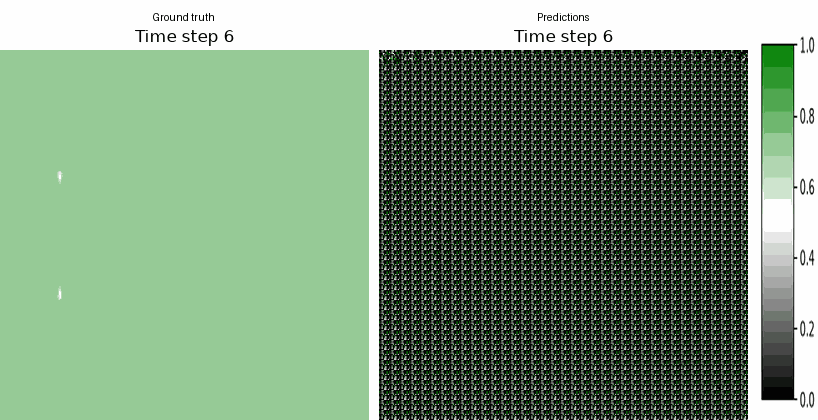

In [12]:
with open(comparison_path, "rb") as f:
    display(ImageDisplay(data=f.read(), format="gif"))

## Load pretrained model

In [ ]:
# Colormap 
black_white_green = LinearSegmentedColormap.from_list(
    'black_white_green',
    ['black', 'white', 'green']
)

# 0. config
args_config = 'data_lanl_fire/config.yaml'
config = Config(filepath=args_config, override_from_env=False, override_from_args=False)
config.in_channels = 4

# 1. Instantiate the model structure
model = AFNONet_Seq2Seq(
    img_size=(config.image_size, config.image_size), patch_size=(config.patch_size, config.patch_size),
    in_chans=config.in_channels, out_chans=config.out_channels,
    context_len=config.context_len, temporal_patch_size=config.temporal_patch_size,
    embed_dim=config.embed_dim, depth=config.depth, num_blocks=config.num_blocks
)


# 2. Load your weights
model_path = 'data_lanl_fire/best_model.pth'
weights = torch.load(model_path, map_location=torch.device('cpu'))
model.load_state_dict(weights['state_dict'])

## Test with pretrained model

## Visualize pretrained model results

## Bonus: Test LANL fire